## CNN for Dog-Cat Classification

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten


d:\Damodarone\Python\venv\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
d:\Damodarone\Python\venv\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
d:\Damodarone\Python\venv\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/resource_handle.proto. Please update the gencode to avoid compatibility violations i

## 1. Load and preprocess the data

The PDF uses local CSV files named `input.csv`, `labels.csv`, `input_test.csv`, and `labels_test.csv`. 
Place them in the working directory or change these paths.

In [2]:
# Change these paths if your CSV files are stored elsewhere.
X_train = np.loadtxt('input.csv', delimiter=',')
Y_train = np.loadtxt('labels.csv', delimiter=',')
X_test = np.loadtxt('input_test.csv', delimiter=',')
Y_test = np.loadtxt('labels_test.csv', delimiter=',')

In [3]:
X_train = X_train.reshape(len(X_train), 100, 100, 3)
Y_train = Y_train.reshape(len(Y_train), 1)
X_test = X_test.reshape(len(X_test), 100, 100, 3)
Y_test = Y_test.reshape(len(Y_test), 1)

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print('Shape of X_train:', X_train.shape)
print('Shape of Y_train:', Y_train.shape)
print('Shape of X_test:', X_test.shape)
print('Shape of Y_test:', Y_test.shape)


Shape of X_train: (2000, 100, 100, 3)
Shape of Y_train: (2000, 1)
Shape of X_test: (400, 100, 100, 3)
Shape of Y_test: (400, 1)


## 2. Display a random training image

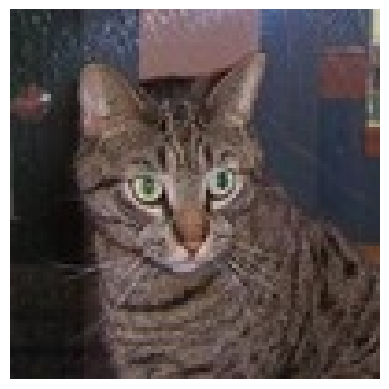

In [5]:
# idx = random.randrange(len(X_train))
idx = 1112
plt.imshow(X_train[idx])
plt.axis('off')
plt.show()


## 3. Build and train the CNN

The PDF shows both the list-based and `model.add()` styles for the same architecture. 
This notebook uses one equivalent model definition.

In [6]:
model = Sequential([
    Conv2D(64, (3, 3), activation='relu', input_shape=(100, 100, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()


d:\Damodarone\Python\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16928)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,083,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,103,777 (4.21 MB)

 Trainable params: 1,103,777 (4.21 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(X_train, Y_train, epochs=2, batch_size=64)


Epoch 1/2
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 171ms/step - accuracy: 0.4985 - loss: 0.7303
Epoch 2/2
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 171ms/step - accuracy: 0.5640 - loss: 0.6801


## 4. Evaluate on the test set

In [8]:
test_loss, test_accuracy = model.evaluate(X_test, Y_test)
print('Test loss:', test_loss)
print('Test accuracy:', test_accuracy)


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.5650 - loss: 0.6703
Test loss: 0.6702637672424316
Test accuracy: 0.5649999976158142


## 5. Predict a random test image

The original PDF maps a thresholded output of 0 to `dog` and 1 to `cat`. This assumes the dataset uses that label encoding.

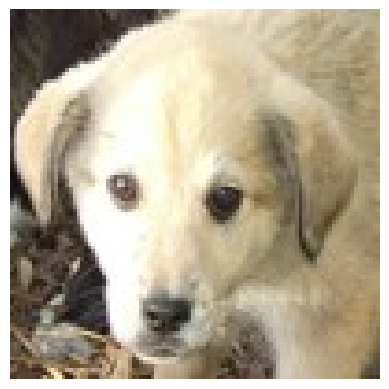

Our model says it is a: dog


In [ ]:
idx2 = random.randrange(len(X_test))
plt.imshow(X_test[idx2])
plt.axis('off')
plt.show()

y_pred = model.predict(X_test[idx2:idx2 + 1], verbose=0)
pred = 'cat' if y_pred[0, 0] > 0.5 else 'dog'
print('Our model says it is a:', pred)
